# NOVA B02 · Dense baseline

Trains the dense NovaLM baseline from random initialisation: a 12-layer decoder-only transformer with 88.1M parameters, trained on 393M tokens of the B01 mix.

**Result:** best validation loss **3.395** (perplexity **29.8**) after 6,000 steps; training and validation loss stay within 0.01 of each other, so the model does not overfit.

## Hardware
Confirms the GPU and the PyTorch build used for this notebook (NVIDIA RTX 5050 Laptop GPU, 8 GB).

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch; print('torch', torch.__version__, '| cuda available:', torch.cuda.is_available())

name, memory.total [MiB]
NVIDIA GeForce RTX 5050 Laptop GPU, 8151 MiB
torch 2.11.0+cu128 | cuda available: True


## Dependencies
Python packages required by this notebook in addition to PyTorch.

In [2]:
!pip install -q tokenizers

## Model (`model.py`)
NovaLM: token embedding tied with the output layer, 12 pre-norm blocks with RMSNorm, rotary position embeddings (RoPE), grouped-query attention (12 query / 4 key-value heads) with QK-normalisation, and SwiGLU feed-forward layers. The same file implements the optional Mixture-of-Experts layer with top-k routing, load-balancing loss and router z-loss used in B03.

In [3]:
%%writefile model.py
"""
Team NOVA - AFML Project
model.py: our own decoder-only transformer, with an optional Mixture-of-Experts FFN.

Differences from the video (GPT-2 style) model, and why:
  * RMSNorm instead of LayerNorm  - no mean-centering, fewer ops, equally stable (LLaMA)
  * RoPE instead of learned position embeddings - relative positions via rotating Q and K
  * SwiGLU feed-forward instead of GELU MLP     - gated FFN, lower loss at equal params
  * No bias terms                                - fewer params, no quality loss at this scale
  * Weight tying (kept from GPT-2)               - input embedding = output projection
  * MoE switch: any layer listed in config.moe_layers uses MoEFFN instead of SwiGLU.
    With moe_layers = () the model is a plain dense transformer (Phase 1).
  * Optional (used by the Base model on C4, off for the small model):
      - Grouped-query attention (n_kv_head < n_head): several query heads share one key/value head
        (LLaMA-2 70B, LLaMA-3, Mistral). Fewer parameters and a 3x smaller KV cache, same quality.
      - QK-norm (qk_norm=True): RMSNorm on each query and key head before RoPE (OLMo-2, Qwen3,
        Gemma-3). Keeps attention logits bounded, which matters in float16 on a T4.

Shapes: B = batch, T = sequence length, C = n_embd, H = n_head, D = head size, V = vocab.
"""

import math
from dataclasses import dataclass, field

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class ModelConfig:
    vocab_size: int = 8192
    block_size: int = 256          # max context length T
    n_layer: int = 6
    n_head: int = 6                # query heads H
    n_kv_head: int = 0             # key/value heads; 0 means = n_head (ordinary multi-head attention)
    qk_norm: bool = False          # RMSNorm on q and k per head
    n_embd: int = 384              # C
    ffn_hidden: int = 1024         # SwiGLU hidden size (~ 8/3 * C, rounded)
    dropout: float = 0.0           # each training token is seen about once, so no dropout
    rope_theta: float = 10000.0
    # --- Mixture of Experts (Phase 2). Empty tuple = dense model. ---
    moe_layers: tuple = ()         # e.g. (1, 3, 5) = MoE in alternate layers
    n_experts: int = 8
    top_k: int = 2
    expert_hidden: int = 512       # each expert is half the dense FFN width


# ----------------------------------------------------------------------------
# Building blocks
# ----------------------------------------------------------------------------
class RMSNorm(nn.Module):
    """y = x / sqrt(mean(x^2) + eps) * g.  Like LayerNorm but without subtracting the mean."""

    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        # compute in float32 for stability under mixed precision
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return xf.type_as(x) * self.weight


def build_rope_cache(T, D, theta, device):
    """Precompute cos/sin for rotary embeddings. Returns two (T, D/2) tensors."""
    inv_freq = 1.0 / (theta ** (torch.arange(0, D, 2, device=device).float() / D))  # (D/2,)
    t = torch.arange(T, device=device).float()                                       # (T,)
    freqs = torch.outer(t, inv_freq)                                                 # (T, D/2)
    return freqs.cos(), freqs.sin()


def apply_rope(x, cos, sin):
    """Rotate each pair (x1, x2) of features by an angle that depends on the position.

    x: (B, H, T, D). Pairing: first half of D with second half.
    After rotation, q·k depends only on the RELATIVE distance between positions.
    """
    D = x.shape[-1]
    x1, x2 = x[..., : D // 2], x[..., D // 2 :]
    cos, sin = cos[None, None], sin[None, None]          # (1, 1, T, D/2)
    return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)


class CausalSelfAttention(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.n_head = cfg.n_head
        self.n_kv_head = cfg.n_kv_head or cfg.n_head                    # Hkv
        assert self.n_head % self.n_kv_head == 0, "query heads must split evenly into KV groups"
        self.head_dim = cfg.n_embd // cfg.n_head                        # D
        self.kv_dim = self.n_kv_head * self.head_dim                    # Hkv * D (= C without GQA)
        self.qkv = nn.Linear(cfg.n_embd, cfg.n_embd + 2 * self.kv_dim, bias=False)  # C -> C + 2*Hkv*D
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)      # C -> C
        if cfg.qk_norm:
            self.q_norm, self.k_norm = RMSNorm(self.head_dim), RMSNorm(self.head_dim)
        else:
            self.q_norm = self.k_norm = None
        self.dropout = cfg.dropout

    def forward(self, x, cos, sin):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split([C, self.kv_dim, self.kv_dim], dim=2)  # (B,T,C), 2 x (B,T,Hkv*D)
        # (B, T, C) -> (B, H, T, D); keys and values have Hkv heads
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        if self.q_norm is not None:                                     # QK-norm, before RoPE
            q, k = self.q_norm(q), self.k_norm(k)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        if self.n_kv_head != self.n_head:                               # GQA: each KV head serves
            rep = self.n_head // self.n_kv_head                         # n_head / n_kv_head query heads
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        # softmax(q k^T / sqrt(D) + causal mask) v, computed by a fused kernel
        y = F.scaled_dot_product_attention(
            q, k, v, is_causal=True, dropout_p=self.dropout if self.training else 0.0
        )                                                               # (B, H, T, D)
        y = y.transpose(1, 2).contiguous().view(B, T, C)                # (B, T, C)
        return self.proj(y)


class SwiGLU(nn.Module):
    """FFN(x) = W_down( SiLU(W_gate x) * (W_up x) ).  Applied to each token independently."""

    def __init__(self, n_embd, hidden):
        super().__init__()
        self.gate = nn.Linear(n_embd, hidden, bias=False)
        self.up = nn.Linear(n_embd, hidden, bias=False)
        self.down = nn.Linear(hidden, n_embd, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))


class MoEFFN(nn.Module):
    """Top-k Mixture of Experts feed-forward layer (Phase 2).

    router:  logits z = W_r h            (one score per expert, per token)
    select:  the top_k experts by z
    combine: y = sum_{i in top-k} g_i * Expert_i(h),  g = softmax over the top-k logits

    Also returns:
      aux_loss  - Switch-Transformer load-balancing loss  E * sum_i f_i * P_i
      z_loss    - mean(logsumexp(z)^2), keeps router logits small and stable
      routing   - dict with logits / chosen experts, used by the research analysis
    """

    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.n_experts = cfg.n_experts
        self.top_k = cfg.top_k
        self.router = nn.Linear(cfg.n_embd, cfg.n_experts, bias=False)
        self.experts = nn.ModuleList(
            [SwiGLU(cfg.n_embd, cfg.expert_hidden) for _ in range(cfg.n_experts)]
        )
        # Research hook (Phase 6, counterfactual routing). Not a parameter, never saved.
        # Set to (mask, idx): mask (N,) bool marks tokens to override, idx (N, k) their forced experts.
        self.force_route = None

    def forward(self, x, valid=None):
        """valid: optional (B, T) bool mask; padding tokens (False) are left out of the balancing
        statistics (aux loss, z-loss). They are still routed, which does not affect real tokens
        because causal attention never lets a real token see the padding after it."""
        B, T, C = x.shape
        h = x.reshape(-1, C)                                            # (N, C), N = B*T
        logits = self.router(h).float()                                 # (N, E)
        probs = logits.softmax(dim=-1)                                  # (N, E)
        top_logits, top_idx = logits.topk(self.top_k, dim=-1)           # (N, k)
        if self.force_route is not None:                                # counterfactual: force experts
            mask, forced = self.force_route
            top_idx = torch.where(mask[:, None], forced, top_idx)
            top_logits = logits.gather(1, top_idx)                      # gates from the forced experts
        gates = top_logits.softmax(dim=-1).type_as(h)                   # (N, k), renormalized

        out = torch.zeros_like(h)
        for e in range(self.n_experts):
            token_pos, slot = (top_idx == e).nonzero(as_tuple=True)     # tokens routed to e
            if token_pos.numel() == 0:
                continue
            y = self.experts[e](h[token_pos])                           # (n_e, C)
            out.index_add_(0, token_pos, y * gates[token_pos, slot, None])

        # load balancing: f_i = fraction of routing slots sent to expert i,
        #                 P_i = mean router probability of expert i
        v = torch.ones(h.shape[0], device=h.device) if valid is None else valid.reshape(-1).float()
        n_valid = v.sum().clamp(min=1.0)
        f = torch.zeros(self.n_experts, device=h.device)
        f.scatter_add_(0, top_idx.reshape(-1), v.repeat_interleave(self.top_k))
        f = f / (n_valid * self.top_k)
        P = (probs * v[:, None]).sum(dim=0) / n_valid
        aux_loss = self.n_experts * (f * P).sum()
        z_loss = (torch.logsumexp(logits, dim=-1).pow(2) * v).sum() / n_valid

        routing = {"logits": logits.detach(), "top_idx": top_idx.detach()}
        return out.view(B, T, C), aux_loss, z_loss, routing


class Block(nn.Module):
    """Pre-norm transformer block:  x = x + attn(norm(x));  x = x + ffn(norm(x))."""

    def __init__(self, cfg: ModelConfig, layer_idx: int):
        super().__init__()
        self.norm1 = RMSNorm(cfg.n_embd)
        self.attn = CausalSelfAttention(cfg)
        self.norm2 = RMSNorm(cfg.n_embd)
        self.is_moe = layer_idx in cfg.moe_layers
        self.ffn = MoEFFN(cfg) if self.is_moe else SwiGLU(cfg.n_embd, cfg.ffn_hidden)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, cos, sin, valid=None):
        x = x + self.drop(self.attn(self.norm1(x), cos, sin))
        if self.is_moe:
            y, aux, z, routing = self.ffn(self.norm2(x), valid)
            return x + self.drop(y), aux, z, routing
        return x + self.drop(self.ffn(self.norm2(x))), None, None, None


# ----------------------------------------------------------------------------
# The full model
# ----------------------------------------------------------------------------
class NovaLM(nn.Module):
    def __init__(self, cfg: ModelConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.blocks = nn.ModuleList([Block(cfg, i) for i in range(cfg.n_layer)])
        self.norm_f = RMSNorm(cfg.n_embd)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight                      # weight tying

        cos, sin = build_rope_cache(cfg.block_size, cfg.n_embd // cfg.n_head, cfg.rope_theta, "cpu")
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

        self.apply(self._init_weights)
        # scale down the layers that write into the residual stream (GPT-2 trick):
        # each block adds 2 contributions, so std / sqrt(2 * n_layer) keeps variance steady
        for name, p in self.named_parameters():
            if name.endswith("proj.weight") or name.endswith("down.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def num_params(self):
        """Total parameters (tied weights counted once)."""
        return sum(p.numel() for p in self.parameters())

    def num_active_params(self):
        """Parameters used per token (MoE: only top_k of n_experts experts)."""
        total = self.num_params()
        for b in self.blocks:
            if b.is_moe:
                per_expert = sum(p.numel() for p in b.ffn.experts[0].parameters())
                total -= (self.cfg.n_experts - self.cfg.top_k) * per_expert
        return total

    def forward(self, idx, targets=None, loss_mask=None, return_routing=False, valid_mask=None):
        """
        idx:       (B, T) token ids
        targets:   (B, T) next-token ids (idx shifted by one) -> teacher forcing
        loss_mask: (B, T) 1 where the loss counts, 0 elsewhere (instruction tuning, Phase 3)
        valid_mask: (B, T) True for real tokens, False for padding (MoE balancing statistics only)
        Returns logits (B, T, V), loss (or None), and an info dict.
        """
        B, T = idx.shape
        assert T <= self.cfg.block_size, f"sequence length {T} > block_size {self.cfg.block_size}"
        x = self.tok_emb(idx)                                           # (B, T, C)
        cos, sin = self.rope_cos[:T], self.rope_sin[:T]

        aux_losses, z_losses, routings = [], [], {}
        for i, block in enumerate(self.blocks):
            x, aux, z, routing = block(x, cos, sin, valid_mask)
            if aux is not None:
                aux_losses.append(aux)
                z_losses.append(z)
                if return_routing:
                    routings[i] = routing
        x = self.norm_f(x)
        logits = self.lm_head(x)                                        # (B, T, V)

        info = {
            "aux_loss": torch.stack(aux_losses).mean() if aux_losses else None,
            "z_loss": torch.stack(z_losses).mean() if z_losses else None,
            "routing": routings,
        }
        if targets is None:
            return logits, None, info

        per_token = F.cross_entropy(
            logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1), reduction="none"
        )
        if loss_mask is None:
            loss = per_token.mean()
        else:
            m = loss_mask.reshape(-1).float()
            loss = (per_token * m).sum() / m.sum().clamp(min=1.0)
        return logits, loss, info

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=50, eot_id=None):
        """Sample tokens one at a time. Stops early when every sequence has produced eot_id."""
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.block_size :]
            logits, _, _ = self(idx_cond)
            logits = logits[:, -1, :].float() / max(temperature, 1e-5)
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float("inf")
            next_id = torch.multinomial(logits.softmax(-1), num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
            if eot_id is not None and (next_id == eot_id).all():
                break
        return idx


Overwriting model.py


## Training loop (`train.py`)
Next-token cross-entropy with AdamW, linear warmup and cosine decay, gradient accumulation, bfloat16 mixed precision, gradient clipping, periodic evaluation, resumable checkpoints and training snapshots for the routing-dynamics study.

In [4]:
%%writefile train.py
"""
Team NOVA - AFML Project
train.py: pretraining (dense or MoE) on the FineWeb-Edu/C4/Wikipedia mix (the earlier small model used TinyStories), with resumable checkpoints.

Fixes compared with the video training loop:
  * the loop counts OPTIMIZER steps; gradient accumulation happens inside each step
  * the LR schedule is computed per optimizer step: linear warmup -> cosine decay to min_lr
  * min_lr < lr (the video had min_lr = 5x lr, so its LR went UP)
  * backward() outside the autocast block; GradScaler only for float16
  * weight decay only on matrices (not on norm gains)
  * checkpoints + CSV log saved to Google Drive, and training resumes after a disconnect
  * periodic weight snapshots, kept for the training-dynamics analysis (Phase 7)
  * Drive-friendly: the resumable checkpoint is written every --resume_every_min minutes (old copies of overwritten
    files can sit in Drive's Bin and count against the quota), free space is checked before every save, and a full
    Drive gives a warning instead of a crash
  * one session per run folder (RUNNING heartbeat), and DONE.json when a run has finished

Example (Colab, T4 GPU):
    python train.py --data_dir /content/drive/MyDrive/nova/data \
                    --out_dir  /content/drive/MyDrive/nova/runs/dense --preset dense
"""

import argparse
import atexit
import csv
import json
import math
import os
import shutil
import socket
import time
import uuid
from contextlib import nullcontext
from dataclasses import asdict

import numpy as np
import torch

from model import ModelConfig, NovaLM

# "Base" model for the C4 corpus (course feedback: scale the SLM up), in the GPT-2-small size class:
# 12 blocks, width 768, 12 query heads sharing 4 key/value heads (grouped-query attention), QK-norm.
# Dense ~88M parameters. MoE: 8 experts of half width in blocks 3, 7, 11 (code indices 2, 6, 10),
# ~131M total / ~88M active per token. Exact counts are printed at the start of training and checked in tests.
BASE = dict(block_size=512, n_layer=12, n_head=12, n_kv_head=4, qk_norm=True,
            n_embd=768, ffn_hidden=2048, expert_hidden=1024)
# Fallback if the T4 is too slow for the Base model: the earlier 60M configuration (10 x 640, plain attention).
BASE60 = dict(block_size=512, n_layer=10, n_head=10, n_embd=640, ffn_hidden=1728, expert_hidden=864)

PRESETS = {
    # Phase 1: dense baseline
    "dense": dict(moe_layers=()),
    # Phase 2: MoE in alternate layers, 8 experts, top-2, with load balancing
    "moe": dict(moe_layers=(1, 3, 5)),
    # Phase 2 ablation: same MoE but trained WITHOUT the load-balancing loss
    "moe_nobal": dict(moe_layers=(1, 3, 5)),
    # Base models on C4 (same recipe as above, larger)
    "base_dense": dict(BASE, moe_layers=()),
    "base_moe": dict(BASE, moe_layers=(2, 6, 10)),
    "base_moe_nobal": dict(BASE, moe_layers=(2, 6, 10)),
    # Placement ablation (TA question): MoE in blocks 1, 2, 5 (code indices 0, 1, 4) instead of 3, 7, 11.
    # Same number of MoE layers, so exactly the same parameter count; only WHERE the experts sit changes.
    "base_moe_early": dict(BASE, moe_layers=(0, 1, 4)),
    "moe_early": dict(moe_layers=(0, 1, 4)),
    "base60_dense": dict(BASE60, moe_layers=()),
    "base60_moe": dict(BASE60, moe_layers=(2, 5, 8)),
    "base60_moe_nobal": dict(BASE60, moe_layers=(2, 5, 8)),
    # tiny config for a quick smoke test (runs on CPU in seconds)
    "tiny": dict(n_layer=2, n_head=2, n_embd=64, ffn_hidden=128, expert_hidden=64, block_size=64),
    "tiny_moe": dict(n_layer=2, n_head=2, n_embd=64, ffn_hidden=128, expert_hidden=64,
                     block_size=64, moe_layers=(1,), n_experts=4),
    "tiny_moe8": dict(n_layer=4, n_head=2, n_embd=64, ffn_hidden=128, expert_hidden=64,
                      block_size=64, moe_layers=(1, 3), n_experts=8),
    # tiny stand-ins for the Base model's attention (grouped-query + QK-norm), used by the Base smoke tests
    "tiny_adv": dict(n_layer=2, n_head=4, n_kv_head=2, qk_norm=True, n_embd=64, ffn_hidden=128,
                     expert_hidden=64, block_size=64),
    "tiny_moe8_adv": dict(n_layer=4, n_head=4, n_kv_head=2, qk_norm=True, n_embd=64, ffn_hidden=128,
                          expert_hidden=64, block_size=64, moe_layers=(1, 3), n_experts=8),
}


# Training defaults per preset (anything passed on the command line still wins). The three Base runs
# share one recipe so that dense vs MoE vs no-balancing stay a fair comparison:
# 8 x 16 x 512 = 65,536 tokens per step x 6,000 steps = 393M tokens. Micro-batch 8 keeps the 88M model
# well inside the T4's 15 GB; the effective batch is 8 x 16 = 128 sequences, the same as before.
PRESET_TRAIN = {
    name: dict(batch_size=8, grad_accum=16, max_steps=6000, lr=6e-4, min_lr=6e-5, snapshot_interval=1500)
    for name in ("base_dense", "base_moe", "base_moe_nobal", "base_moe_early",
                 "base60_dense", "base60_moe", "base60_moe_nobal")
}


def uses_balancing(preset):
    """The *_nobal presets are the ablation: same MoE, trained WITHOUT the load-balancing loss."""
    return not preset.endswith("nobal")


def get_args():
    p = argparse.ArgumentParser()
    p.add_argument("--data_dir", required=True)
    p.add_argument("--out_dir", required=True)
    p.add_argument("--preset", default="dense", choices=list(PRESETS))
    p.add_argument("--max_steps", type=int, default=10000, help="optimizer steps")
    p.add_argument("--batch_size", type=int, default=32, help="sequences per micro-batch")
    p.add_argument("--grad_accum", type=int, default=4, help="micro-batches per optimizer step")
    p.add_argument("--lr", type=float, default=1e-3)
    p.add_argument("--min_lr", type=float, default=1e-4)
    p.add_argument("--warmup_steps", type=int, default=300)
    p.add_argument("--weight_decay", type=float, default=0.1)
    p.add_argument("--grad_clip", type=float, default=1.0)
    p.add_argument("--aux_coef", type=float, default=0.01, help="load-balancing loss weight")
    p.add_argument("--z_coef", type=float, default=1e-3, help="router z-loss weight")
    p.add_argument("--eval_interval", type=int, default=250)
    p.add_argument("--eval_iters", type=int, default=50)
    p.add_argument("--snapshot_interval", type=int, default=1000,
                   help="save weights-only snapshots for the training-dynamics analysis")
    p.add_argument("--resume_every_min", type=float, default=45,
                   help="write the resumable checkpoint (weights + optimizer) to out_dir at most this often")
    p.add_argument("--save_best", action="store_true",
                   help="also keep ckpt_best.pt (not used later: pretrained models are always taken at the last step)")
    p.add_argument("--seed", type=int, default=1337)
    p.add_argument("--no_resume", action="store_true")
    p.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    preset = p.parse_known_args()[0].preset
    p.set_defaults(**PRESET_TRAIN.get(preset, {}))
    return p.parse_args()


# ----------------------------------------------------------------------------
# Data
# ----------------------------------------------------------------------------
def val_dev_end(val_path, eot_id=0):
    """Index where the validation file is split in two (validation / test), at a document boundary.
    [0, dev_end)  = development half: research probe set, forgetting checks during fine-tuning
    [dev_end, :)  = TEST half: touched only by final_eval.py (notebook 06)."""
    data = np.memmap(val_path, dtype=np.uint16, mode="r")
    mid = len(data) // 2
    return mid + int(np.argmax(data[mid:] == eot_id)) + 1


class Batcher:
    """Random windows of block_size+1 tokens from a uint16 memmap: x = w[:-1], y = w[1:].
    limit: only sample windows that end before this token index (e.g. the development half)."""

    def __init__(self, path, block_size, batch_size, device, seed, limit=None):
        self.path, self.T, self.B, self.device = path, block_size, batch_size, device
        self.n = len(np.memmap(path, dtype=np.uint16, mode="r"))
        if limit is not None:
            self.n = min(self.n, int(limit))
        self.rng = np.random.default_rng(seed)

    def get(self):
        data = np.memmap(self.path, dtype=np.uint16, mode="r")   # re-open: avoids memmap RAM growth
        ix = self.rng.integers(0, self.n - self.T - 1, size=self.B)
        w = np.stack([data[i : i + self.T + 1] for i in ix]).astype(np.int64)
        w = torch.from_numpy(w)
        x, y = w[:, :-1].contiguous(), w[:, 1:].contiguous()
        if self.device.startswith("cuda"):
            return (x.pin_memory().to(self.device, non_blocking=True),
                    y.pin_memory().to(self.device, non_blocking=True))
        return x.to(self.device), y.to(self.device)


def lr_at(step, args):
    """Linear warmup to lr, then cosine decay to min_lr at max_steps."""
    if step < args.warmup_steps:
        return args.lr * (step + 1) / args.warmup_steps
    progress = (step - args.warmup_steps) / max(1, args.max_steps - args.warmup_steps)
    return args.min_lr + 0.5 * (args.lr - args.min_lr) * (1 + math.cos(math.pi * min(progress, 1.0)))


def make_optimizer(model, args):
    decay = [p for p in model.parameters() if p.requires_grad and p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.dim() < 2]
    groups = [{"params": decay, "weight_decay": args.weight_decay},
              {"params": no_decay, "weight_decay": 0.0}]
    fused = args.device.startswith("cuda")
    return torch.optim.AdamW(groups, lr=args.lr, betas=(0.9, 0.95), eps=1e-8, fused=fused)


@torch.no_grad()
def evaluate(model, batchers, eval_iters, ctx):
    model.eval()
    out = {}
    for split, b in batchers.items():
        b.rng = np.random.default_rng(999)       # same eval batches every time -> comparable numbers
        losses = []
        for _ in range(eval_iters):
            x, y = b.get()
            with ctx:
                _, loss, _ = model(x, y)
            losses.append(loss.item())
        out[split] = float(np.mean(losses))
    model.train()
    return out


def sample_text(model, tok, device, eot_id, prompt="Once upon a time", n_tokens=120):
    if tok is None:
        return ""
    idx = torch.tensor([tok.encode(prompt).ids], device=device)
    out = model.generate(idx, n_tokens, temperature=0.8, top_k=50, eot_id=eot_id)
    model.train()
    return tok.decode(out[0].tolist())


# ----------------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------------
LOCK_STALE_S = 600        # a RUNNING heartbeat older than 10 minutes belongs to a dead session


def read_lock(path):
    """(seconds since the last heartbeat, session id) of a RUNNING file, or (None, None).
    A heartbeat written on THIS machine by a process that no longer exists (e.g. after a kernel restart) counts as
    stale at once; one written on another machine counts as alive until it is LOCK_STALE_S old."""
    try:
        with open(path) as f:
            d = json.load(f)
        age = time.time() - float(d["t"])
    except Exception:
        return None, None
    if d.get("host") == socket.gethostname() and d.get("pid"):
        try:
            os.kill(int(d["pid"]), 0)          # signal 0: only checks that the process exists
        except ProcessLookupError:
            age = float("inf")
        except (PermissionError, OSError, ValueError):
            pass
    return age, d.get("id")


def write_json(path, obj):
    with open(path + ".tmp", "w") as f:
        json.dump(obj, f)
    os.replace(path + ".tmp", path)


# ---------------- saving to Google Drive without filling it ----------------
# Every overwrite of a file on Drive can leave the old copy in Drive's Bin, which counts against the 15 GB quota.
# So big files are written rarely: the resumable checkpoint every --resume_every_min minutes (not at every evaluation),
# with Adam's two moment estimates stored in bfloat16 (one third smaller), and every save checks the free space first.
def compact_optimizer_state(sd):
    """Copy of optimizer.state_dict() with floating-point state (Adam's moments) in bfloat16. The live optimizer is not
    touched. load_state_dict casts the values back to the parameters' float32; the rounding happens once per resume."""
    small = lambda k, v: v.to(torch.bfloat16) if torch.is_tensor(v) and v.is_floating_point() and k != "step" else v
    return {"state": {i: {k: small(k, v) for k, v in st.items()} for i, st in sd["state"].items()},
            "param_groups": sd["param_groups"]}


def nbytes(obj):
    if torch.is_tensor(obj):
        return obj.numel() * obj.element_size()
    if isinstance(obj, dict):
        return sum(nbytes(v) for v in obj.values())
    if isinstance(obj, (list, tuple)):
        return sum(nbytes(v) for v in obj)
    return 0


DRIVE_FULL = ("Google Drive may be full: open drive.google.com -> Bin -> Empty bin (and delete files you do not need). "
              "Training continues and tries again at the next evaluation.")


def safe_save(state, path):
    """Atomic save (write .tmp, then rename). Returns False (with a clear message) instead of crashing when there is
    not enough free space, so a full Drive never kills a training run."""
    try:
        free = shutil.disk_usage(os.path.dirname(os.path.abspath(path))).free
    except OSError:
        free = None
    need = 1.1 * nbytes(state) + 50e6
    if free is not None and free < need:
        print(f"WARNING: only {free / 1e9:.2f} GB free, {os.path.basename(path)} needs {need / 1e9:.2f} GB; not saved. "
              + DRIVE_FULL)
        return False
    try:
        torch.save(state, path + ".tmp")
        os.replace(path + ".tmp", path)
        return True
    except (OSError, RuntimeError) as e:
        try:
            os.remove(path + ".tmp")
        except OSError:
            pass
        print(f"WARNING: could not save {os.path.basename(path)} ({type(e).__name__}: {str(e)[:120]}). " + DRIVE_FULL)
        return False


def save_until_done(state, path, tries=60):
    """The final weights must reach Drive: retry every minute (up to an hour) while the user frees space."""
    for i in range(tries):
        if safe_save(state, path):
            return True
        print(f"   retrying in 60 s ({i + 1}/{tries}); the trained model is still in memory, do not stop the cell")
        time.sleep(60)
    raise RuntimeError(f"could not save {path}")


def main():
    args = get_args()
    os.makedirs(args.out_dir, exist_ok=True)
    torch.manual_seed(args.seed)

    meta = json.load(open(os.path.join(args.data_dir, "meta.json")))
    eot_id = meta["special_tokens"]["<|endoftext|>"]
    try:
        from tokenizers import Tokenizer
        tok = Tokenizer.from_file(os.path.join(args.data_dir, "tokenizer.json"))
    except Exception:
        tok = None

    cfg = ModelConfig(vocab_size=meta["vocab_size"], **PRESETS[args.preset])
    use_aux = uses_balancing(args.preset)
    device = args.device
    model = NovaLM(cfg).to(device)
    optimizer = make_optimizer(model, args)

    # mixed precision: bfloat16 if the GPU supports it (A100/L4), else float16 + GradScaler (T4)
    if device.startswith("cuda"):
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        ctx = torch.autocast(device_type="cuda", dtype=dtype)
    else:
        dtype, ctx = torch.float32, nullcontext()
    scaler = torch.amp.GradScaler("cuda", enabled=(dtype == torch.float16))

    # ---------------- one session per run folder ----------------
    # Teammates share one Drive folder. Two Colab sessions training the same run would overwrite each other's
    # checkpoints, so a running session keeps a heartbeat in RUNNING (rewritten every 2 minutes) and a second
    # session refuses to start while that heartbeat is fresh (stale after 10 min, or at once if its process is gone).
    lock_path = os.path.join(args.out_dir, "RUNNING")
    done_path = os.path.join(args.out_dir, "DONE.json")
    session = uuid.uuid4().hex
    if not args.no_resume:
        age, owner = read_lock(lock_path)
        if age is not None and age < LOCK_STALE_S and owner != session:
            print(f"Another session is training {args.out_dir} right now (heartbeat {age / 60:.1f} min ago); "
                  f"not starting a second copy. If that session is dead, run this again in "
                  f"{(LOCK_STALE_S - age) / 60:.0f} min, or delete {lock_path}.")
            return

    # ---------------- resume ----------------
    ckpt_path = os.path.join(args.out_dir, "ckpt_last.pt")
    step, best_val = 0, float("inf")
    if os.path.exists(ckpt_path) and not args.no_resume:
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        if "optimizer" not in ck:                         # finished runs keep weights only (saves Drive space)
            print(f"Run already finished at step {ck['step']} (best val {ck['best_val']:.4f}); nothing to do.")
            if not os.path.exists(done_path):
                write_json(done_path, {"step": ck["step"], "best_val": ck["best_val"]})
            return
        model.load_state_dict(ck["model"])
        optimizer.load_state_dict(ck["optimizer"])
        scaler.load_state_dict(ck["scaler"])
        step, best_val = ck["step"], ck["best_val"]
        print(f"Resumed from step {step} (best val {best_val:.4f})")

    batchers = {
        "train": Batcher(os.path.join(args.data_dir, "train.bin"), cfg.block_size, args.batch_size, device, args.seed + step),
        "val": Batcher(os.path.join(args.data_dir, "val.bin"), cfg.block_size, args.batch_size, device, 10_000 + step),
    }
    eval_batchers = {k: Batcher(b.path, cfg.block_size, args.batch_size, device, 999) for k, b in batchers.items()}

    tokens_per_step = args.batch_size * args.grad_accum * cfg.block_size
    print(f"Preset: {args.preset} | params: {model.num_params()/1e6:.2f}M total, "
          f"{model.num_active_params()/1e6:.2f}M active per token")
    print(f"Device: {device} | dtype: {dtype} | tokens/step: {tokens_per_step:,} | "
          f"total tokens: {tokens_per_step * args.max_steps / 1e6:.0f}M")
    with open(os.path.join(args.out_dir, "config.json"), "w") as f:
        json.dump({"model": asdict(cfg), "train": vars(args)}, f, indent=2)

    log_path = os.path.join(args.out_dir, "log.csv")
    new_log = not os.path.exists(log_path) or step == 0
    log_f = open(log_path, "w" if new_log else "a", newline="")
    log = csv.writer(log_f)
    if new_log:
        log.writerow(["step", "tokens", "lr", "train_loss", "val_loss", "aux_loss", "z_loss", "tok_per_s"])

    def state(full=False, half=False):
        """full: also optimizer + scaler (needed to resume). half: weights in float16 (snapshots: half the size;
        only used for routing analysis, where float16 rounding is far below the margins we measure)."""
        sd = model.state_dict()
        if half:
            sd = {k: (v.half() if v.is_floating_point() else v) for k, v in sd.items()}
        st = {"model": sd, "config": asdict(cfg), "step": step, "best_val": best_val}
        if full:
            st.update(optimizer=compact_optimizer_state(optimizer.state_dict()), scaler=scaler.state_dict())
        return st

    def save(path, full=True, half=False):       # atomic: a disconnect never leaves a broken file
        return safe_save(state(full, half), path)

    def beat():
        if not args.no_resume:
            write_json(lock_path, {"t": time.time(), "id": session, "host": socket.gethostname(), "pid": os.getpid()})

    def release():                       # on normal exit, an error or a manual stop (not when Colab kills the VM)
        if not args.no_resume and read_lock(lock_path)[1] == session:
            try:
                os.remove(lock_path)
            except OSError:
                pass

    beat()
    atexit.register(release)
    last_beat = last_full = time.time()

    model.train()
    t0, last_aux, last_z = time.time(), float("nan"), float("nan")
    while step < args.max_steps:
        if time.time() - last_beat > 120:
            beat()
            last_beat = time.time()
        lr = lr_at(step, args)
        for g in optimizer.param_groups:
            g["lr"] = lr

        # ---- one optimizer step = grad_accum micro-batches ----
        for _ in range(args.grad_accum):
            x, y = batchers["train"].get()
            with ctx:
                _, loss, info = model(x, y)
                total = loss
                if info["aux_loss"] is not None:
                    if use_aux:
                        total = total + args.aux_coef * info["aux_loss"]
                    total = total + args.z_coef * info["z_loss"]
                    last_aux, last_z = info["aux_loss"].item(), info["z_loss"].item()
            scaler.scale(total / args.grad_accum).backward()      # backward outside autocast
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), args.grad_clip)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        step += 1

        # ---- evaluation, logging, checkpoints ----
        if step % args.eval_interval == 0 or step == args.max_steps:
            dt = time.time() - t0
            tok_s = tokens_per_step * args.eval_interval / dt
            losses = evaluate(model, eval_batchers, args.eval_iters, ctx)
            eta_min = (args.max_steps - step) * tokens_per_step / tok_s / 60
            print(f"step {step:6d} | lr {lr:.2e} | train {losses['train']:.4f} | val {losses['val']:.4f} "
                  f"| aux {last_aux:.3f} | {tok_s/1e3:.0f}k tok/s | ETA {eta_min:.0f} min")
            log.writerow([step, step * tokens_per_step, f"{lr:.6g}", f"{losses['train']:.5f}",
                          f"{losses['val']:.5f}", f"{last_aux:.5f}", f"{last_z:.5f}", f"{tok_s:.0f}"])
            log_f.flush()
            if losses["val"] < best_val:
                best_val = losses["val"]
                if args.save_best:
                    save(os.path.join(args.out_dir, "ckpt_best.pt"), full=False)
            # resumable checkpoint at most every resume_every_min minutes (a disconnect loses at most that much)
            if step < args.max_steps and time.time() - last_full >= 60 * args.resume_every_min:
                if save(ckpt_path, full=True):
                    last_full = time.time()
                    print(f"   saved resumable checkpoint at step {step}")
            t0 = time.time()
        if step % args.snapshot_interval == 0:
            save(os.path.join(args.out_dir, f"snapshot_step{step:06d}.pt"), full=False, half=True)
        if step % (args.eval_interval * 4) == 0 or step == args.max_steps:
            print("   sample:", sample_text(model, tok, device, eot_id).replace("\n", " ")[:400])
            t0 = time.time()

    log_f.close()
    save_until_done(state(full=False), ckpt_path)    # finished: weights only (float32), no optimizer state
    if not args.no_resume:
        write_json(done_path, {"step": step, "best_val": best_val})     # later notebooks use only finished runs
    release()
    print(f"Done. Best val loss {best_val:.4f} (perplexity {math.exp(best_val):.2f})")


if __name__ == "__main__":
    main()


Overwriting train.py


## Smoke test
A 1.1M-parameter model trained for 60 steps; the falling loss confirms that data loading, the model and the optimiser are wired correctly.

In [5]:
!python train.py --data_dir /content/drive/MyDrive/nova_base/data --out_dir /content/smoke --preset tiny \
    --max_steps 60 --eval_interval 20 --eval_iters 5 --lr 3e-3 --warmup_steps 10 --no_resume

Preset: tiny | params: 1.13M total, 1.13M active per token
Device: cuda | dtype: torch.bfloat16 | tokens/step: 8,192 | total tokens: 0M
step     20 | lr 2.77e-03 | train 7.9932 | val 8.0404 | aux nan | 38k tok/s | ETA 0 min
step     40 | lr 1.19e-03 | train 7.5709 | val 7.6322 | aux nan | 62k tok/s | ETA 0 min
step     60 | lr 1.03e-04 | train 7.5522 | val 7.6112 | aux nan | 62k tok/s | ETA 0 min
   sample: Once upon a time in for,,, a- on. the has will the you a as and to for in in the The  to with,, the this in. a the I the isThe's a  you the in to-,,  and to you the., it, in,,. and.. a , as has by a, and of has in  to- the a to,. the you, as in, with as a. of- , in  the the.,. or a at. or...-.. of this the,
Done. Best val loss 7.6112 (perplexity 2020.80)


## Throughput
A 30-step run of the full 88M model measures training speed and the expected duration of the full 393M-token run.

In [6]:
!python train.py --data_dir /content/drive/MyDrive/nova_base/data --out_dir /content/bench --preset base_dense --max_steps 30 \
    --eval_interval 10 --eval_iters 5 --warmup_steps 5 --no_resume
import pandas as pd
b = pd.read_csv('/content/bench/log.csv'); tps = b.tok_per_s.iloc[-1]
print(f'{tps:,.0f} tokens/s -> full run (393M tokens) = about {393e6 / tps / 3600:.1f} hours')

Preset: base_dense | params: 88.10M total, 88.10M active per token
Device: cuda | dtype: torch.bfloat16 | tokens/step: 65,536 | total tokens: 2M
step     10 | lr 5.67e-04 | train 7.6248 | val 7.6411 | aux nan | 22k tok/s | ETA 1 min
step     20 | lr 2.79e-04 | train 7.5640 | val 7.5594 | aux nan | 22k tok/s | ETA 0 min
step     30 | lr 6.21e-05 | train 7.4844 | val 7.4911 | aux nan | 22k tok/s | ETA 0 min
   sample: Once upon a time in for,,, a- on and the has will we you- as and to the in the the one and more with,, the and in the a the I the is to the a- you and in a a,, to and to the the.  The in the,. The.
Done. Best val loss 7.4911 (perplexity 1792.04)
22,220 tokens/s -> full run (393M tokens) = about 4.9 hours


## Full training run
6,000 optimiser steps × 65,536 tokens (batch 8 × 16 accumulation × 512 tokens), learning rate 6e-4 with 300 warmup steps and cosine decay to 6e-5. The run was trained on the RTX 5050 (about 6 hours, 18k tokens/s); re-running the cell detects the finished run and does not train again.

In [7]:
!python train.py --data_dir /content/drive/MyDrive/nova_base/data --out_dir /content/drive/MyDrive/nova_base/runs/dense --preset base_dense

Run already finished at step 6000 (best val 3.3951); nothing to do.


## Loss curves
Training and validation loss against tokens seen. Perplexity is e^loss: 29.8 means the model is, on average, as uncertain as a uniform choice among about 30 tokens.

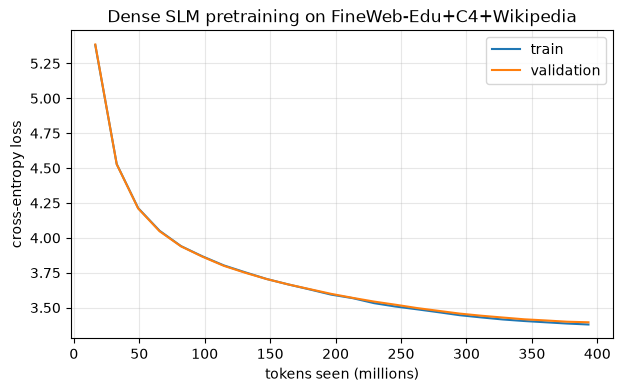

best val loss 3.3950 | perplexity 29.82


In [8]:
import pandas as pd, matplotlib.pyplot as plt, math, os
log = pd.read_csv('/content/drive/MyDrive/nova_base/runs/dense/log.csv')
plt.figure(figsize=(7,4))
plt.plot(log.tokens/1e6, log.train_loss, label='train'); plt.plot(log.tokens/1e6, log.val_loss, label='validation')
plt.xlabel('tokens seen (millions)'); plt.ylabel('cross-entropy loss'); plt.legend(); plt.grid(alpha=.3)
plt.title('Dense SLM pretraining on FineWeb-Edu+C4+Wikipedia')
os.makedirs('/content/drive/MyDrive/nova_base/results', exist_ok=True); plt.savefig('/content/drive/MyDrive/nova_base/results/dense_loss_curve.png', dpi=150, bbox_inches='tight'); plt.show()
best = log.val_loss.min(); print(f'best val loss {best:.4f} | perplexity {math.exp(best):.2f}')

## Text samples
Continuations of three prompts (temperature 0.8, top-k 50). The text is fluent and on-topic in style, with invented facts, as expected for an 88M model trained on 0.39B tokens.

In [9]:
import torch
from tokenizers import Tokenizer
from model import ModelConfig, NovaLM
tok = Tokenizer.from_file('/content/drive/MyDrive/nova_base/data/tokenizer.json'); eot = tok.token_to_id('<|endoftext|>')
ck = torch.load('/content/drive/MyDrive/nova_base/runs/dense/ckpt_last.pt', map_location='cuda', weights_only=False)
cfg = ModelConfig(**{**ck['config'], 'moe_layers': tuple(ck['config']['moe_layers'])})
model = NovaLM(cfg).cuda(); model.load_state_dict(ck['model']); model.eval()
for prompt in ['The history of the city began', 'Scientists have discovered that', 'If you want to improve your writing,']:
    idx = torch.tensor([tok.encode(prompt).ids], device='cuda')
    out = model.generate(idx, 200, temperature=0.8, top_k=50, eot_id=eot)
    print(tok.decode(out[0].tolist()), '\n' + '-'*80)

The history of the city began in the late 1800's by the arrival of the first wave of European settlers. By the early 1900's, some of the first wave of immigration took place in the United States.
The wave of immigration continued in the mid-19th century, until the mid-19th century.
The history of immigration is well known, as the U.S. government made its first state law on the grounds that immigrants were already born in the United States. In 1879, the U.S. Senate passed the New Deal Act, which passed the Eugenics Act of 1885. When it was introduced into the United States, it passed the Ninth Circuit in 1888, passed the New Deal Act, established the United States as the first state to enforce immigration.
The U.S. government began to take a more active approach to the problems of immigration in the 1960s. The first major United States laws were passed in 1888, a change to 
--------------------------------------------------------------------------------
Scientists have discovered that a